In [30]:
%pip install xarray netCDF4 geopandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [31]:
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt

In [32]:
kelp = xr.open_dataset(r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens\Data Athens\California dataset\LandsatKelpBiomass_2026_Q2_withmetadata.nc")
kelp

<xarray.Dataset> Size: 4GB
Dimensions:     (station: 593427, time: 170)
Coordinates:
  * time        (time) datetime64[ns] 1kB 1984-02-15 1984-05-15 ... 2026-05-15
Dimensions without coordinates: station
Data variables:
    latitude    (station) float64 5MB ...
    longitude   (station) float64 5MB ...
    year        (time) int32 680B ...
    quarter     (time) int16 340B ...
    biomass     (time, station) float64 807MB ...
    biomass_se  (time, station) float64 807MB ...
    area        (time, station) float64 807MB ...
    area_se     (time, station) float64 807MB ...
    passes      (time, station) int16 202MB ...
    passes5     (time, station) int16 202MB ...
    passes7     (time, station) int16 202MB ...
    passes8     (time, station) int16 202MB ...
Attributes: (12/50)
    title:                           SBC LTER: Time series of quarterly NetCD...
    summary:                         Wet biomass (kg) of giant kelp (Macrocys...
    keywords:                        biomass, canopy, LTER, populations, Sant...
    id:                              knb-lter-sbc.74.34
    doi:                             doi:10.6073/pasta/5b441f39c0876ef9010687...
    keywords_vocabulary:             LTER Controlled Vocabulary V1
    ...                              ...
    geospatial_vertical_resolution:  1
    time_coverage_start:             1984-01-1
    time_coverage_end:               2026-06-30
    time_coverage_duration:          P36Y
    time_coverage_resolution:        P3M
    metadata_link:                   https://portal.edirepository.org/nis/met...

In [33]:
for name, variable in kelp.variables.items():
    print(
        f"{name}: "
        f"dimensions={variable.dims}, "
        f"shape={variable.shape}, "
        f"units={variable.attrs.get('units', 'not specified')}"
    )

kelp.attrs
kelp.coords

latitude: dimensions=('station',), shape=(593427,), units=degrees_north
longitude: dimensions=('station',), shape=(593427,), units=degrees_east
year: dimensions=('time',), shape=(170,), units=year
quarter: dimensions=('time',), shape=(170,), units=quarter of year
biomass: dimensions=('time', 'station'), shape=(170, 593427), units=wet Kg/900m^2 pixel
biomass_se: dimensions=('time', 'station'), shape=(170, 593427), units=wet Kg/900m^2 pixel
area: dimensions=('time', 'station'), shape=(170, 593427), units=m^2 canopy/900m^2 pixel
area_se: dimensions=('time', 'station'), shape=(170, 593427), units=m^2 canopy/900m^2 pixel
passes: dimensions=('time', 'station'), shape=(170, 593427), units=number of Landsat images used to make mean for each pixel, each quarter
passes5: dimensions=('time', 'station'), shape=(170, 593427), units=number of Landsat 4/5 TM images used to make the mean for each pixel, each quarter
passes7: dimensions=('time', 'station'), shape=(170, 593427), units=number of Landsat 

Coordinates:
  * time     (time) datetime64[ns] 1kB 1984-02-15 1984-05-15 ... 2026-05-15

In [34]:
print("First date:", kelp["time"].min().values)
print("Last date:", kelp["time"].max().values)
print("Number of dates:", kelp["time"].size)

First date: 1984-02-15T00:00:00.000000000
Last date: 2026-05-15T00:00:00.000000000
Number of dates: 170


In [35]:
kelp["biomass"].attrs

{'ancillary_variables': 'biomass_se',
 'units': 'wet Kg/900m^2 pixel',
 'long_name': 'kelp biomass',
 'standard_name': 'kelp biomass',
 'valid_min': np.int32(0),
 'valid_max': np.int32(20000),
 'comment': 'Data derived from Satellite images'}

In [36]:
missing = kelp["biomass"].isnull().sum().compute().item()
total = kelp["biomass"].size

print("Missing values:", missing)
print(f"Missing percentage: {100 * missing / total:.2f}%")

Missing values: 20033817
Missing percentage: 19.86%


FISHING BLOCKS

In [37]:
fishing_blocks = gpd.read_file(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens\Data Athens\California dataset\fishing_blocks.geojson"
)

fishing_blocks.head()

print("Columns:", fishing_blocks.columns.tolist())
print("Coordinate reference system:", fishing_blocks.crs)
print("Number of blocks:", len(fishing_blocks))

DataSourceError: C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens\Data Athens\California dataset\fishing_blocks.geojson: No such file or directory

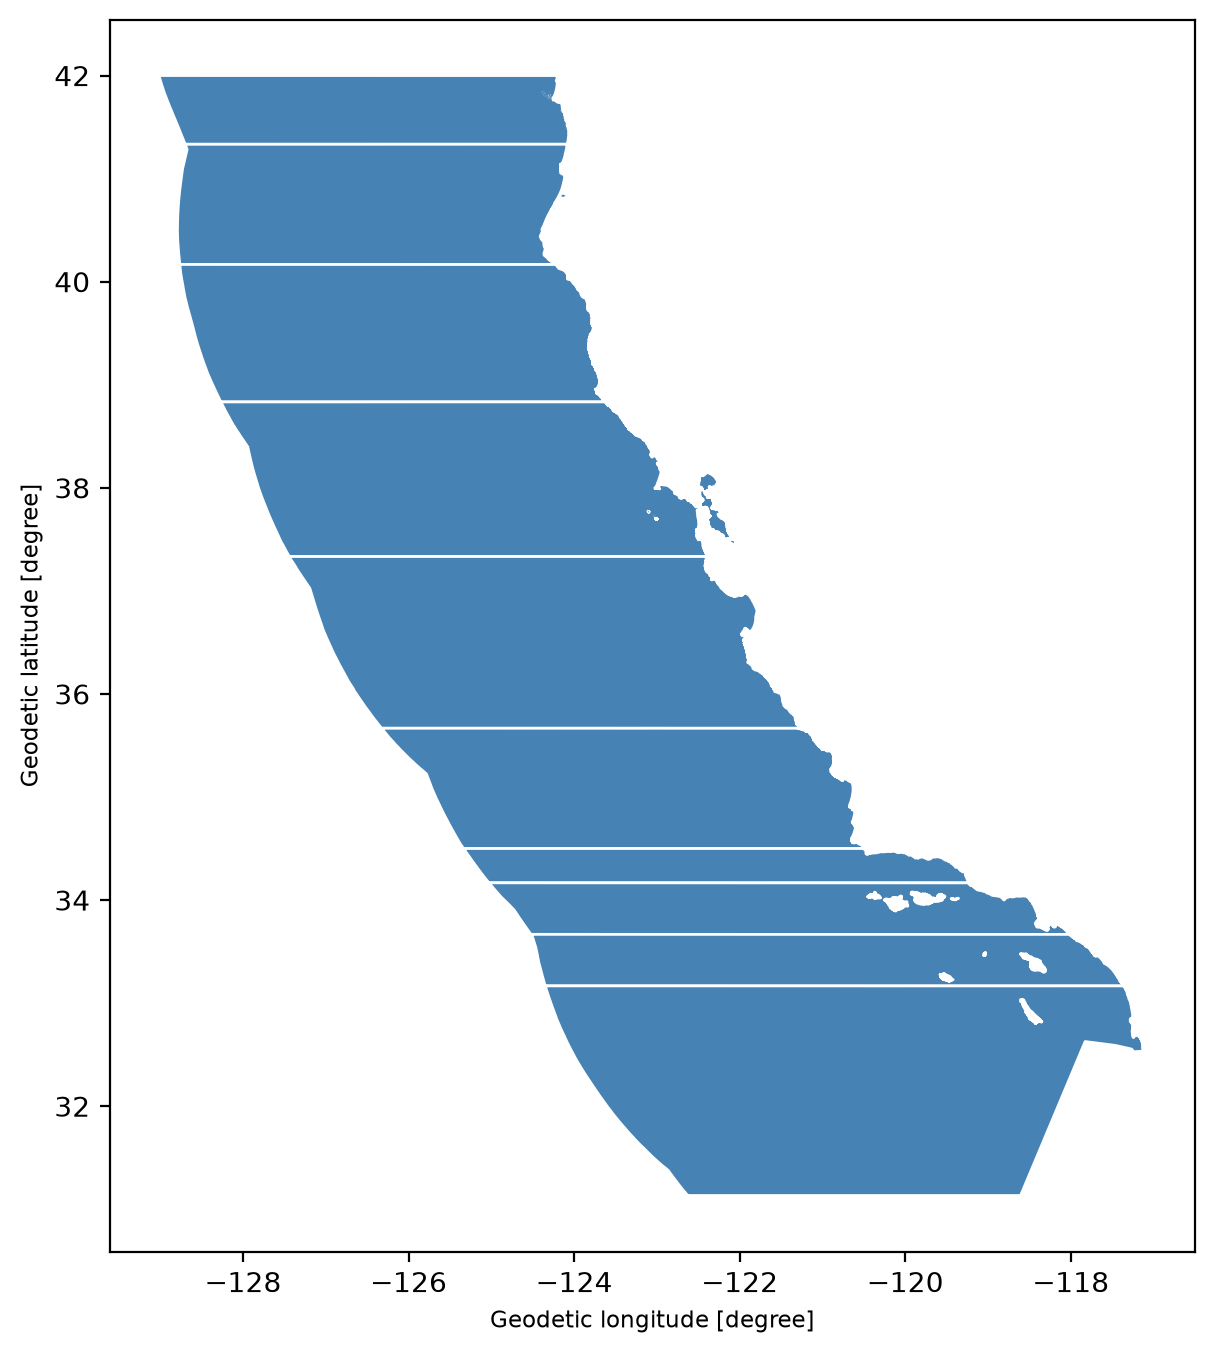

In [ ]:
fishing_blocks.plot(
    figsize=(10, 8),
    color="steelblue",
    edgecolor="white",
    linewidth=1
)

plt.show()

FISH CATCHES ANNUAL DATA

In [ ]:
python -m pip install playwright
python -m playwright install chromium

SyntaxError: invalid syntax (2644619165.py, line 1)

Which files from the automatic pointer downloader were not downloaded or are empty?

In [ ]:
from pathlib import Path

folder = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research"
    r"\Visiting Researcher Athens\kelp-fisheries-stability-ML\downloads"
)

# Exact filename endings shown in your screenshots
areas = [
    "bodega_bay",
    "eureka_area",
    "fort_bragg_area",
    "inland_waters_area",
    "los_angeles_area",
    "monterey_area",
    "morro_bay_area",
    "sacramento_delta_area",
    "san_diego_area",
    "san_francisco_area",
    "santa_barbara_area",
]

if not folder.is_dir():
    raise FileNotFoundError(folder)

# Include subfolders; ignore empty files and Excel temporary files
existing = {
    p.stem.lower()
    for p in folder.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".xlsx", ".xls"}
    and not p.name.startswith("~$")
    and p.stat().st_size > 0
}

missing = [
    (year, area)
    for year in range(1980, 2026)
    for area in areas
    if f"landings_{year}_{area}" not in existing
]

print("Expected combinations: 506")
print(f"Found combinations: {506 - len(missing)}")
print(f"Missing or empty: {len(missing)}")

for year, area in missing:
    print(f"landings_{year}_{area}")

Which files of catches are empty?

In [ ]:
for p in folder.rglob("*"):
    if (
        p.is_file()
        and p.suffix.lower() in {".xlsx", ".xls"}
        and p.stat().st_size == 0
    ):
        print("Empty file:", p)

#All 2025 files are unaccesible, and 4 Inland Waters files ar unaccessible.
Now, create one united dataset.

In [ ]:
from pathlib import Path
import re
import pandas as pd

# Run from your project folder.
project = Path.cwd()
downloads = project / "downloads"
output = project / "fisheries_merged.xlsx"

if not downloads.is_dir():
    raise FileNotFoundError(f"Downloads folder not found: {downloads}")


def normalise(value):
    """Match column headings regardless of capitalisation."""
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def numeric_values(series):
    """Keep zeros; convert missing or confidential values to NA."""
    text = series.astype("string").str.strip()
    text = text.str.replace(r"^\((.*)\)$", r"-\1", regex=True)
    text = text.str.replace(r"[$,\s]", "", regex=True)
    return pd.to_numeric(text, errors="coerce")


frames = []
issues = []
files_merged = 0

files = sorted(
    p for p in downloads.glob("landings_*.*")
    if p.suffix.lower() in {".xlsx", ".xls"}
    and not p.name.startswith("~$")
)

for file in files:
    match = re.fullmatch(
        r"landings_(\d{4})_(.+)",
        file.stem,
        flags=re.IGNORECASE,
    )

    if not match:
        issues.append((file.name, "Filename not recognised"))
        continue

    year = int(match.group(1))
    port_area = match.group(2).replace("_", " ").title()

    try:
        sheets = pd.read_excel(file, sheet_name=None, header=None)
        file_frames = []

        for sheet_name, raw in sheets.items():
            header_row = None
            columns = None

            # Find headings below any report title lines.
            for row_number in range(min(50, len(raw))):
                found = {}

                for column_number, cell in enumerate(raw.iloc[row_number]):
                    heading = normalise(cell)

                    for field, choices in aliases.items():
                        if heading in choices:
                            found.setdefault(field, column_number)

                if all(field in found for field in aliases):
                    header_row = row_number
                    columns = found
                    break

            if header_row is None:
                issues.append((
                    file.name,
                    f"Sheet '{sheet_name}': headings not recognised; skipped",
                ))
                continue

            data = raw.iloc[header_row + 1:].copy()

            result = pd.DataFrame({
                "Species": data.iloc[:, columns["Species"]],
                "Pounds": data.iloc[:, columns["Pounds"]],
                "Value": data.iloc[:, columns["Value"]],
            })

            result["Species"] = (
                result["Species"].astype("string").str.strip()
            )

            # Remove blank labels, repeated headings, and total rows.
            species_key = result["Species"].map(normalise)

            keep = (
                result["Species"].notna()
                & result["Species"].ne("")
                & ~species_key.isin(
                    aliases["Species"] | {"total", "grandtotal", "subtotal"}
                )
                & ~result["Species"].str.contains(
                    r"^(?:grand\s+total|subtotal|total)\b",
                    case=False,
                    na=False,
                )
            )

            result = result.loc[keep].copy()

            # Remove text-only footer rows. Retain suppression codes
            # when present in either measurement column.
            has_measure = (
                result["Pounds"].notna() | result["Value"].notna()
            )
            result = result.loc[has_measure].copy()

            result["Pounds"] = numeric_values(result["Pounds"])
            result["Value"] = numeric_values(result["Value"])

            result.insert(0, "Port_Area", port_area)
            result.insert(0, "Year", year)

            if not result.empty:
                file_frames.append(result)

        if not file_frames:
            raise ValueError("No data rows found with recognised headings")

        frames.extend(file_frames)
        files_merged += 1

    except Exception as error:
        issues.append((file.name, str(error)))


if not frames:
    for filename, problem in issues:
        print(f"{filename}: {problem}")

    raise RuntimeError(
        "No files could be merged. Check the source report headings."
    )

merged = pd.concat(frames, ignore_index=True)

merged = merged[
    ["Year", "Port_Area", "Species", "Pounds", "Value"]
].sort_values(
    ["Year", "Port_Area", "Species"],
    ignore_index=True,
)

# Flag duplicate keys without automatically deleting or summing them.
duplicate_rows = merged.duplicated(
    subset=["Year", "Port_Area", "Species"],
    keep=False,
)

# Excel permits 1,048,576 rows, including the header.
if len(merged) > 1_048_575:
    raise ValueError("Dataset exceeds the Excel single-sheet row limit.")

with pd.ExcelWriter(output, engine="openpyxl") as writer:
    merged.to_excel(writer, sheet_name="Landings", index=False)

    if issues:
        pd.DataFrame(
            issues, columns=["File", "Problem"]
        ).to_excel(writer, sheet_name="Merge_Issues", index=False)

    if duplicate_rows.any():
        merged.loc[duplicate_rows].to_excel(
            writer, sheet_name="Duplicate_Keys", index=False
        )

    worksheet = writer.sheets["Landings"]
    worksheet.freeze_panes = "A2"
    worksheet.auto_filter.ref = worksheet.dimensions

    for column, width in {
        "A": 10,
        "B": 26,
        "C": 45,
        "D": 20,
        "E": 20,
    }.items():
        worksheet.column_dimensions[column].width = width

    for row in worksheet.iter_rows(min_row=2, min_col=4, max_col=5):
        for cell in row:
            cell.number_format = "#,##0.00"


print(f"\nSaved: {output}")
print(f"Excel files found: {len(files)}")
print(f"Files merged: {files_merged}")
print(f"Rows: {len(merged):,}")
print(f"Years: {merged['Year'].min()}–{merged['Year'].max()}")
print(f"Port areas: {merged['Port_Area'].nunique()}")
print(f"Missing Pounds values: {merged['Pounds'].isna().sum():,}")
print(f"Missing Value values: {merged['Value'].isna().sum():,}")
print(f"Rows with duplicate year–area–species keys: {duplicate_rows.sum():,}")
print(f"Merge issues: {len(issues)}")

if issues:
    print("\nReview the Merge_Issues sheet:")
    for filename, problem in issues:
        print(f"  {filename}: {problem}")

if duplicate_rows.any():
    print("\nReview the Duplicate_Keys sheet before analysis.")

landings_1980_bodega_bay.xlsx: name 'aliases' is not defined
landings_1980_eureka_area.xlsx: name 'aliases' is not defined
landings_1980_fort_bragg_area.xlsx: name 'aliases' is not defined
landings_1980_los_angeles_area.xlsx: name 'aliases' is not defined
landings_1980_monterey_area.xlsx: name 'aliases' is not defined
landings_1980_morro_bay_area.xlsx: name 'aliases' is not defined
landings_1980_sacramento_delta_area.xlsx: name 'aliases' is not defined
landings_1980_san_diego_area.xlsx: name 'aliases' is not defined
landings_1980_san_francisco_area.xlsx: name 'aliases' is not defined
landings_1980_santa_barbara_area.xlsx: name 'aliases' is not defined
landings_1981_bodega_bay.xlsx: name 'aliases' is not defined
landings_1981_eureka_area.xlsx: name 'aliases' is not defined
landings_1981_fort_bragg_area.xlsx: name 'aliases' is not defined
landings_1981_inland_waters_area.xlsx: name 'aliases' is not defined
landings_1981_los_angeles_area.xlsx: name 'aliases' is not defined
landings_1981_m

RuntimeError: No files could be merged. Check the source report headings.

Add the Species Groups and ID's to Fisheries Dataset

In [ ]:
import pandas as pd
from pathlib import Path

#Rename "Species" to "Species Name" in Fishery dataset
file_path = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens"
    r"\kelp-fisheries-stability-ML\fisheries_merged.xlsx"
)

fisheries = pd.read_excel(file_path)

fisheries = fisheries.rename(columns={"Species": "Species Name"})

# Save back to the same Excel file
fisheries.to_excel(file_path, index=False)

display(fisheries.head())

#Add a matching Species ID, Species Group and CCL Category to Fishery dataset by Species Name
from pathlib import Path
import pandas as pd

folder = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens"
    r"\kelp-fisheries-stability-ML"
)

fisheries_path = folder / "fisheries_merged.xlsx"
metadata_path = folder / "data" / "processed" / "species_metadata.xlsx"

fisheries = pd.read_excel(fisheries_path)
metadata = pd.read_excel(metadata_path, dtype=str)

metadata_columns = ["Species ID", "Species Group", "CCL Category"]
metadata = metadata[["Species Name"] + metadata_columns].copy()

# Create matching keys, ignoring extra spaces and capitalization
def matching_key(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.casefold()
    )

fisheries["_species_key"] = matching_key(fisheries["Species Name"])
metadata["_species_key"] = matching_key(metadata["Species Name"])

# Remove empty keys and identical metadata records
metadata = metadata.dropna(subset=["_species_key"])
metadata = metadata.loc[metadata["_species_key"].ne("")]
metadata = metadata[["_species_key"] + metadata_columns].drop_duplicates()

# Prevent duplicate metadata names from multiplying fisheries rows
if metadata["_species_key"].duplicated().any():
    conflicts = metadata.loc[
        metadata["_species_key"].duplicated(keep=False)
    ]
    display(conflicts)
    raise ValueError("Conflicting metadata for the same species. Review above.")

# Replace metadata columns if this code has been run before
fisheries = fisheries.drop(columns=metadata_columns, errors="ignore")

fisheries = fisheries.merge(
    metadata,
    on="_species_key",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Show species that did not match
unmatched = fisheries.loc[
    fisheries["_merge"].eq("left_only"), "Species Name"
].drop_duplicates()

print(f"Unmatched species: {len(unmatched)}")
display(unmatched.to_frame())

fisheries = fisheries.drop(columns=["_species_key", "_merge"])

# Save the updated dataset
fisheries.to_excel(fisheries_path, index=False)

display(fisheries.head(10))

,Year,Port_Area,Species Name,Pounds,Value,Species ID,Species Group,CCL Category
0,1980,Bodega Bay,"Blackfish, Sacramento",NaN,NaN,NaN,NaN,NaN
1,1980,Bodega Bay,Butterfish (Pacific pompano),NaN,NaN,80.0,Roundfish,Finfish
2,1980,Bodega Bay,Cabezon,NaN,NaN,261.0,Roundfish,Finfish
3,1980,Bodega Bay,Cabezon,NaN,NaN,261.0,Roundfish,Finfish
4,1980,Bodega Bay,Carp,NaN,NaN,NaN,NaN,NaN


Unmatched species: 23


,Species Name
0,"Blackfish, Sacramento"
4,Carp
6,"Clam, freshwater"
86,"Shrimp, brine"
1098,"Crayfish, signal"
1269,"Bass, striped"
1793,Hitch
1871,Sucker
2616,"Catfish, unspecified"
2996,"Crayfish, unspecified"


,Year,Port_Area,Species Name,Pounds,Value,Species ID,Species Group,CCL Category
0,1980,Bodega Bay,"Blackfish, Sacramento",NaN,NaN,NaN,NaN,NaN
1,1980,Bodega Bay,Butterfish (Pacific pompano),NaN,NaN,80,Roundfish,Finfish
2,1980,Bodega Bay,Cabezon,NaN,NaN,261,Roundfish,Finfish
3,1980,Bodega Bay,Cabezon,NaN,NaN,261,Roundfish,Finfish
4,1980,Bodega Bay,Carp,NaN,NaN,NaN,NaN,NaN
5,1980,Bodega Bay,Carp,NaN,NaN,NaN,NaN,NaN
6,1980,Bodega Bay,"Clam, freshwater",NaN,NaN,NaN,NaN,NaN
7,1980,Bodega Bay,"Crab, Dungeness",176862.0,164268.0,800,Crabs,Crustaceans
8,1980,Bodega Bay,"Crab, Dungeness",NaN,NaN,800,Crabs,Crustaceans
9,1980,Bodega Bay,"Crab, Dungeness",NaN,NaN,800,Crabs,Crustaceans


Create a graph on types of fish type (CCL category) by volume, caught over the years 1980 - 2024

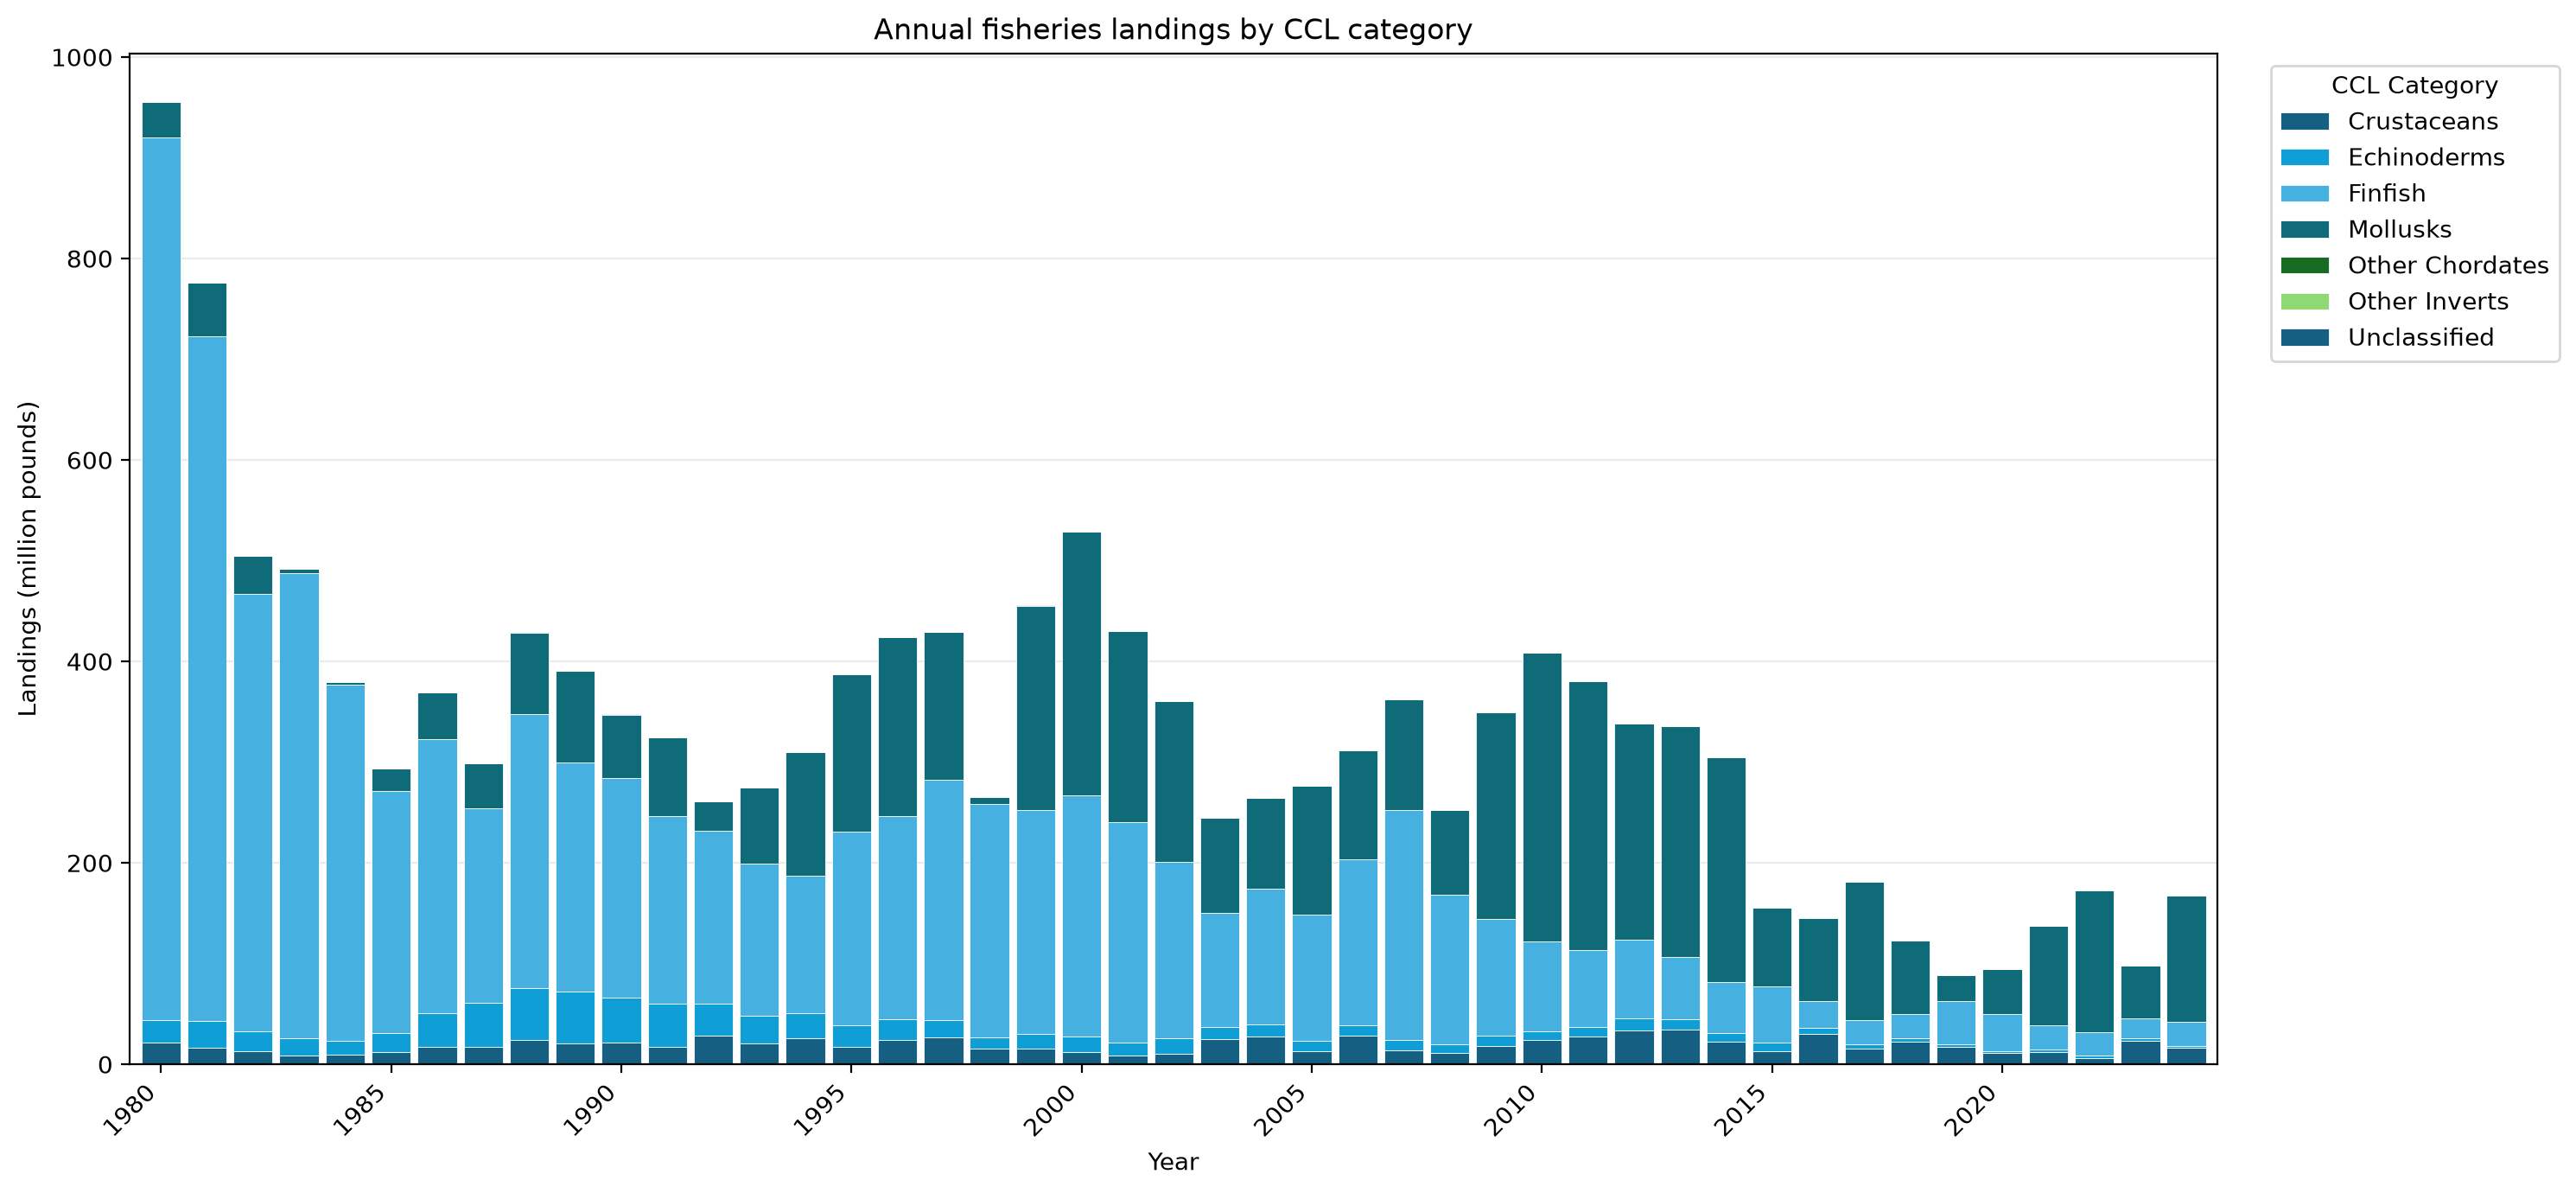

Saved: C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens\kelp-fisheries-stability-ML\Figures\annual_landings_by_CCL_category.png


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens"
    r"\kelp-fisheries-stability-ML"
)

figures_folder = project / "Figures"
figures_folder.mkdir(parents=True, exist_ok=True)

# Load data
data = pd.read_excel(project / "fisheries_merged.xlsx")

data["Year"] = pd.to_numeric(data["Year"], errors="coerce")
data["Pounds"] = pd.to_numeric(
    data["Pounds"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

data["CCL Category"] = (
    data["CCL Category"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unclassified")
)

data = data.dropna(subset=["Year", "Pounds"])
data["Year"] = data["Year"].astype(int)

annual = (
    data.groupby(["Year", "CCL Category"])["Pounds"]
    .sum(min_count=1)
    .unstack()
    .sort_index()
)

# Create chart
fig_annual, ax = plt.subplots(figsize=(15, 7))

(annual / 1_000_000).plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#156082", "#0F9ED5", "#46B1E1",
           "#0F6B78", "#196B24", "#8ED973"],
    width=0.85,
    edgecolor="white",
    linewidth=0.3
)

ax.set_title("Annual fisheries landings by CCL category")
ax.set_xlabel("Year")
ax.set_ylabel("Landings (million pounds)")

positions = list(range(0, len(annual), 5))
ax.set_xticks(positions)
ax.set_xticklabels(annual.index[positions], rotation=45, ha="right")

ax.legend(title="CCL Category", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig_annual.tight_layout()

# Save before displaying
output_path = figures_folder / "annual_landings_by_CCL_category.png"
fig_annual.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
print("Saved:", output_path)

In [ ]:
from pathlib import Path

figures_folder = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens"
    r"\kelp-fisheries-stability-ML\Figures"
)

figures_folder.mkdir(parents=True, exist_ok=True)

ax.figure.savefig(
    figures_folder / "annual_landings_by_CCL_category.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

Now, create Sankey chart by volumes of (1) Species CCL category, (2) Species Group and (3) Species Name

In [ ]:
from pathlib import Path
import pandas as pd
import plotly.graph_objects as go

# Paths
project = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens"
    r"\kelp-fisheries-stability-ML"
)

figures_folder = project / "Figures"
figures_folder.mkdir(parents=True, exist_ok=True)

# Load data directly from Excel
data = pd.read_excel(project / "fisheries_merged.xlsx")

stages = ["CCL Category", "Species Group", "Species Name"]

# Clean classification labels
for column in stages:
    data[column] = (
        data[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Unclassified")
    )

# Convert landings to numbers
data["Pounds"] = pd.to_numeric(
    data["Pounds"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

data = data.loc[data["Pounds"].gt(0)].copy()

if data.empty:
    raise ValueError("No positive Pounds values found.")

flows = data.groupby(stages, as_index=False)["Pounds"].sum()

# Create nodes for each of the three stages
palette = [
    "#156082", "#0F9ED5", "#46B1E1",
    "#0F6B78", "#196B24", "#8ED973"
]

node_index = {}
labels = []
colours = []
positions_x = []

for stage_number, column in enumerate(stages):
    names = (
        flows.groupby(column)["Pounds"]
        .sum()
        .sort_values(ascending=False)
        .index
    )

    for i, name in enumerate(names):
        node_index[(stage_number, name)] = len(labels)
        labels.append(name)
        colours.append(palette[i % len(palette)])
        positions_x.append([0.01, 0.50, 0.99][stage_number])

# Create links weighted by pounds
sources = []
targets = []
volumes = []
link_colours = []

for stage_number in range(2):
    left = stages[stage_number]
    right = stages[stage_number + 1]

    links = flows.groupby([left, right], as_index=False)["Pounds"].sum()

    for _, row in links.iterrows():
        source = node_index[(stage_number, row[left])]
        target = node_index[(stage_number + 1, row[right])]

        sources.append(source)
        targets.append(target)
        volumes.append(float(row["Pounds"]))

        hex_colour = colours[source]
        r, g, b = (
            int(hex_colour[i:i + 2], 16)
            for i in (1, 3, 5)
        )
        link_colours.append(f"rgba({r},{g},{b},0.35)")

# Create the Sankey figure
height = max(900, max(flows[c].nunique() for c in stages) * 24)

fig_sankey = go.Figure(go.Sankey(
    arrangement="snap",
    valueformat=",.0f",
    valuesuffix=" lb",
    node=dict(
        label=labels,
        color=colours,
        x=positions_x,
        pad=12,
        thickness=18,
        line=dict(color="white", width=0.5)
    ),
    link=dict(
        source=sources,
        target=targets,
        value=volumes,
        color=link_colours
    )
))

fig_sankey.update_layout(
    title="Fisheries landings by category, group and species",
    font=dict(family="Arial", size=12, color="#243746"),
    paper_bgcolor="white",
    width=1600,
    height=height,
    margin=dict(l=30, r=280, t=110, b=30)
)

for x, heading in zip([0.01, 0.50, 0.99], stages):
    fig_sankey.add_annotation(
        x=x,
        y=1.025,
        xref="paper",
        yref="paper",
        text=f"<b>{heading}</b>",
        showarrow=False,
        xanchor="center"
    )

# Save as PNG
output_path = figures_folder / "Sankey_Species Volumes.png"

fig_sankey.write_image(
    str(output_path),
    format="png",
    scale=2
)

print("Saved:", output_path)

Saved: C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens\kelp-fisheries-stability-ML\Figures\Sankey_Species Volumes.png


Create a map of the Port Area, Fishing Blocks and Kelp (3 variables).

In [ ]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

# Project folder
project = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens"
    r"\kelp-fisheries-stability-ML"
)

# Load GeoJSON files
ports = gpd.read_file(
    project / "data" / "California_Ports_-_OSPR_[ds353].geojson"
)

fishing_blocks = gpd.read_file(
    project / "data" / "fishing_blocks.geojson"
)

# Check coordinate reference systems
if ports.crs is None or fishing_blocks.crs is None:
    raise ValueError(
        "One dataset has no CRS. Check its source before assigning a CRS."
    )

# Project both layers to California Albers (coordinates in metres)
ports = ports.to_crs(epsg=3310)
fishing_blocks = fishing_blocks.to_crs(epsg=3310)

# Remove missing or empty geometries
ports = ports.loc[
    ports.geometry.notna() & ~ports.geometry.is_empty
].copy()

fishing_blocks = fishing_blocks.loc[
    fishing_blocks.geometry.notna() & ~fishing_blocks.geometry.is_empty
].copy()

# Create map
fig_map, ax_map = plt.subplots(figsize=(12, 14))

fishing_blocks.plot(
    ax=ax_map,
    facecolor="#B8DFE6",
    edgecolor="white",
    linewidth=0.5,
    zorder=1
)

ports.plot(
    ax=ax_map,
    color="#156082",
    markersize=35,
    edgecolor="white",
    linewidth=0.6,
    label="Ports",
    zorder=3
)

ax_map.set_title("California ports and fishing blocks", fontsize=16)
ax_map.set_aspect("equal")
ax_map.set_axis_off()
ax_map.legend(loc="upper right")

fig_map.tight_layout()

# Save image
figures_folder = project / "Figures"
figures_folder.mkdir(parents=True, exist_ok=True)

output_path = figures_folder / "California_Ports_and_Fishing_Blocks.png"

fig_map.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved:", output_path)

# Inspect available port attributes for adding labels later
print("Port columns:", ports.columns.tolist())
display(ports.head())

Create port-centered catchment areas via buffers in geoJSON 

In [ ]:
from pathlib import Path
import geopandas as gpd

# Project folder
project = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens"
    r"\kelp-fisheries-stability-ML"
)

# Load port locations
ports = gpd.read_file(
    project / "data" / "California_Ports_-_OSPR_[ds353].geojson"
)

if ports.crs is None:
    raise ValueError("Ports have no CRS. Check the source CRS first.")

# Remove missing or empty geometries
ports = ports.loc[
    ports.geometry.notna() & ~ports.geometry.is_empty
].copy()

if not ports.geometry.geom_type.isin(["Point", "MultiPoint"]).all():
    raise ValueError("The ports dataset must contain point locations.")

# Create a stable identifier if one does not already exist
if "Port_ID" not in ports.columns:
    ports["Port_ID"] = range(1, len(ports) + 1)

# California Albers: coordinates and buffer distances in metres
ports_projected = ports.to_crs(epsg=3310)

# Output folder
output_folder = project / "data" / "processed" / "port_buffers"
output_folder.mkdir(parents=True, exist_ok=True)

for distance_km in [25, 50, 75, 100]:
    buffers = ports_projected.copy()

    buffers["Buffer_km"] = distance_km
    buffers.geometry = ports_projected.geometry.buffer(
        distance_km * 1000,
        resolution=64
    )

    # Export GeoJSON in longitude/latitude
    buffers = buffers.to_crs(epsg=4326)

    output_path = output_folder / f"Ports_Buffer_{distance_km}km.geojson"

    buffers.to_file(
        output_path,
        driver="GeoJSON",
        index=False
    )

    print(f"Saved {len(buffers)} buffers: {output_path}")

Create a set of data-map of California merged fishing blocks

In [ ]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

project = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens"
    r"\kelp-fisheries-stability-ML"
)

# Load fishing blocks
fishing_blocks = gpd.read_file(
    project / "data" / "fishing_blocks.geojson"
)

if fishing_blocks.crs is None:
    raise ValueError("Fishing blocks have no CRS. Check the source CRS.")

# Remove missing or empty geometries
blocks = fishing_blocks.loc[
    fishing_blocks.geometry.notna() & ~fishing_blocks.geometry.is_empty,
    ["geometry"]
].copy()

blocks = blocks.to_crs(epsg=3310)

# Repair invalid geometries
blocks["geometry"] = blocks.geometry.make_valid()

# Merge all blocks and remove internal boundaries
ocean_area = blocks.dissolve().reset_index(drop=True)
ocean_area["Name"] = "Fishing-block coverage"

# Save GeoJSON
output_folder = project / "data" / "processed"
output_folder.mkdir(parents=True, exist_ok=True)

ocean_area.to_crs(epsg=4326).to_file(
    output_folder / "California_Fishing_Block_Coverage.geojson",
    driver="GeoJSON",
    index=False
)

# Create map
fig_ocean, ax_ocean = plt.subplots(figsize=(12, 14))

ocean_area.plot(
    ax=ax_ocean,
    facecolor="#B8DFE6",
    edgecolor="#156082",
    linewidth=0.6
)

ax_ocean.set_title("California fishing-block coverage", fontsize=16)
ax_ocean.set_axis_off()

fig_ocean.tight_layout()

# Save map
figures_folder = project / "Figures"
figures_folder.mkdir(parents=True, exist_ok=True)

fig_ocean.savefig(
    figures_folder / "California_Fishing_Block_Coverage.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

Intersect the port buffers with the merged fishing block area to obtain sea-covered buffer area of catchment of every port.

In [ ]:
from pathlib import Path
import geopandas as gpd

project = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens"
    r"\kelp-fisheries-stability-ML"
)

buffer_folder = project / "data" / "processed" / "port_buffers"

# Load the merged fishing area
fishing_area = gpd.read_file(
    project / "data" / "processed"
    / "California_Fishing_Block_Coverage.geojson"
)

if fishing_area.crs is None:
    raise ValueError("Fishing area has no CRS.")

fishing_area = fishing_area.to_crs(epsg=3310)
fishing_area.geometry = fishing_area.geometry.make_valid()

# Clip each buffer file and overwrite it
for distance_km in [25, 50, 75, 100]:
    file_path = buffer_folder / f"Ports_Buffer_{distance_km}km.geojson"

    buffers = gpd.read_file(file_path)

    if buffers.crs is None:
        raise ValueError(f"No CRS found in {file_path.name}")

    buffers = buffers.to_crs(epsg=3310)
    buffers.geometry = buffers.geometry.make_valid()

    clipped = gpd.clip(
        buffers,
        fishing_area,
        keep_geom_type=True
    )

    clipped = clipped.loc[
        clipped.geometry.notna() & ~clipped.geometry.is_empty
    ].copy()

    # Save in longitude/latitude, preserving port attributes
    clipped.to_crs(epsg=4326).to_file(
        file_path,
        driver="GeoJSON",
        mode="w",
        index=False
    )

    print(
        f"Overwritten: {file_path.name} "
        f"({len(clipped)} of {len(buffers)} port buffers retained)"
    )

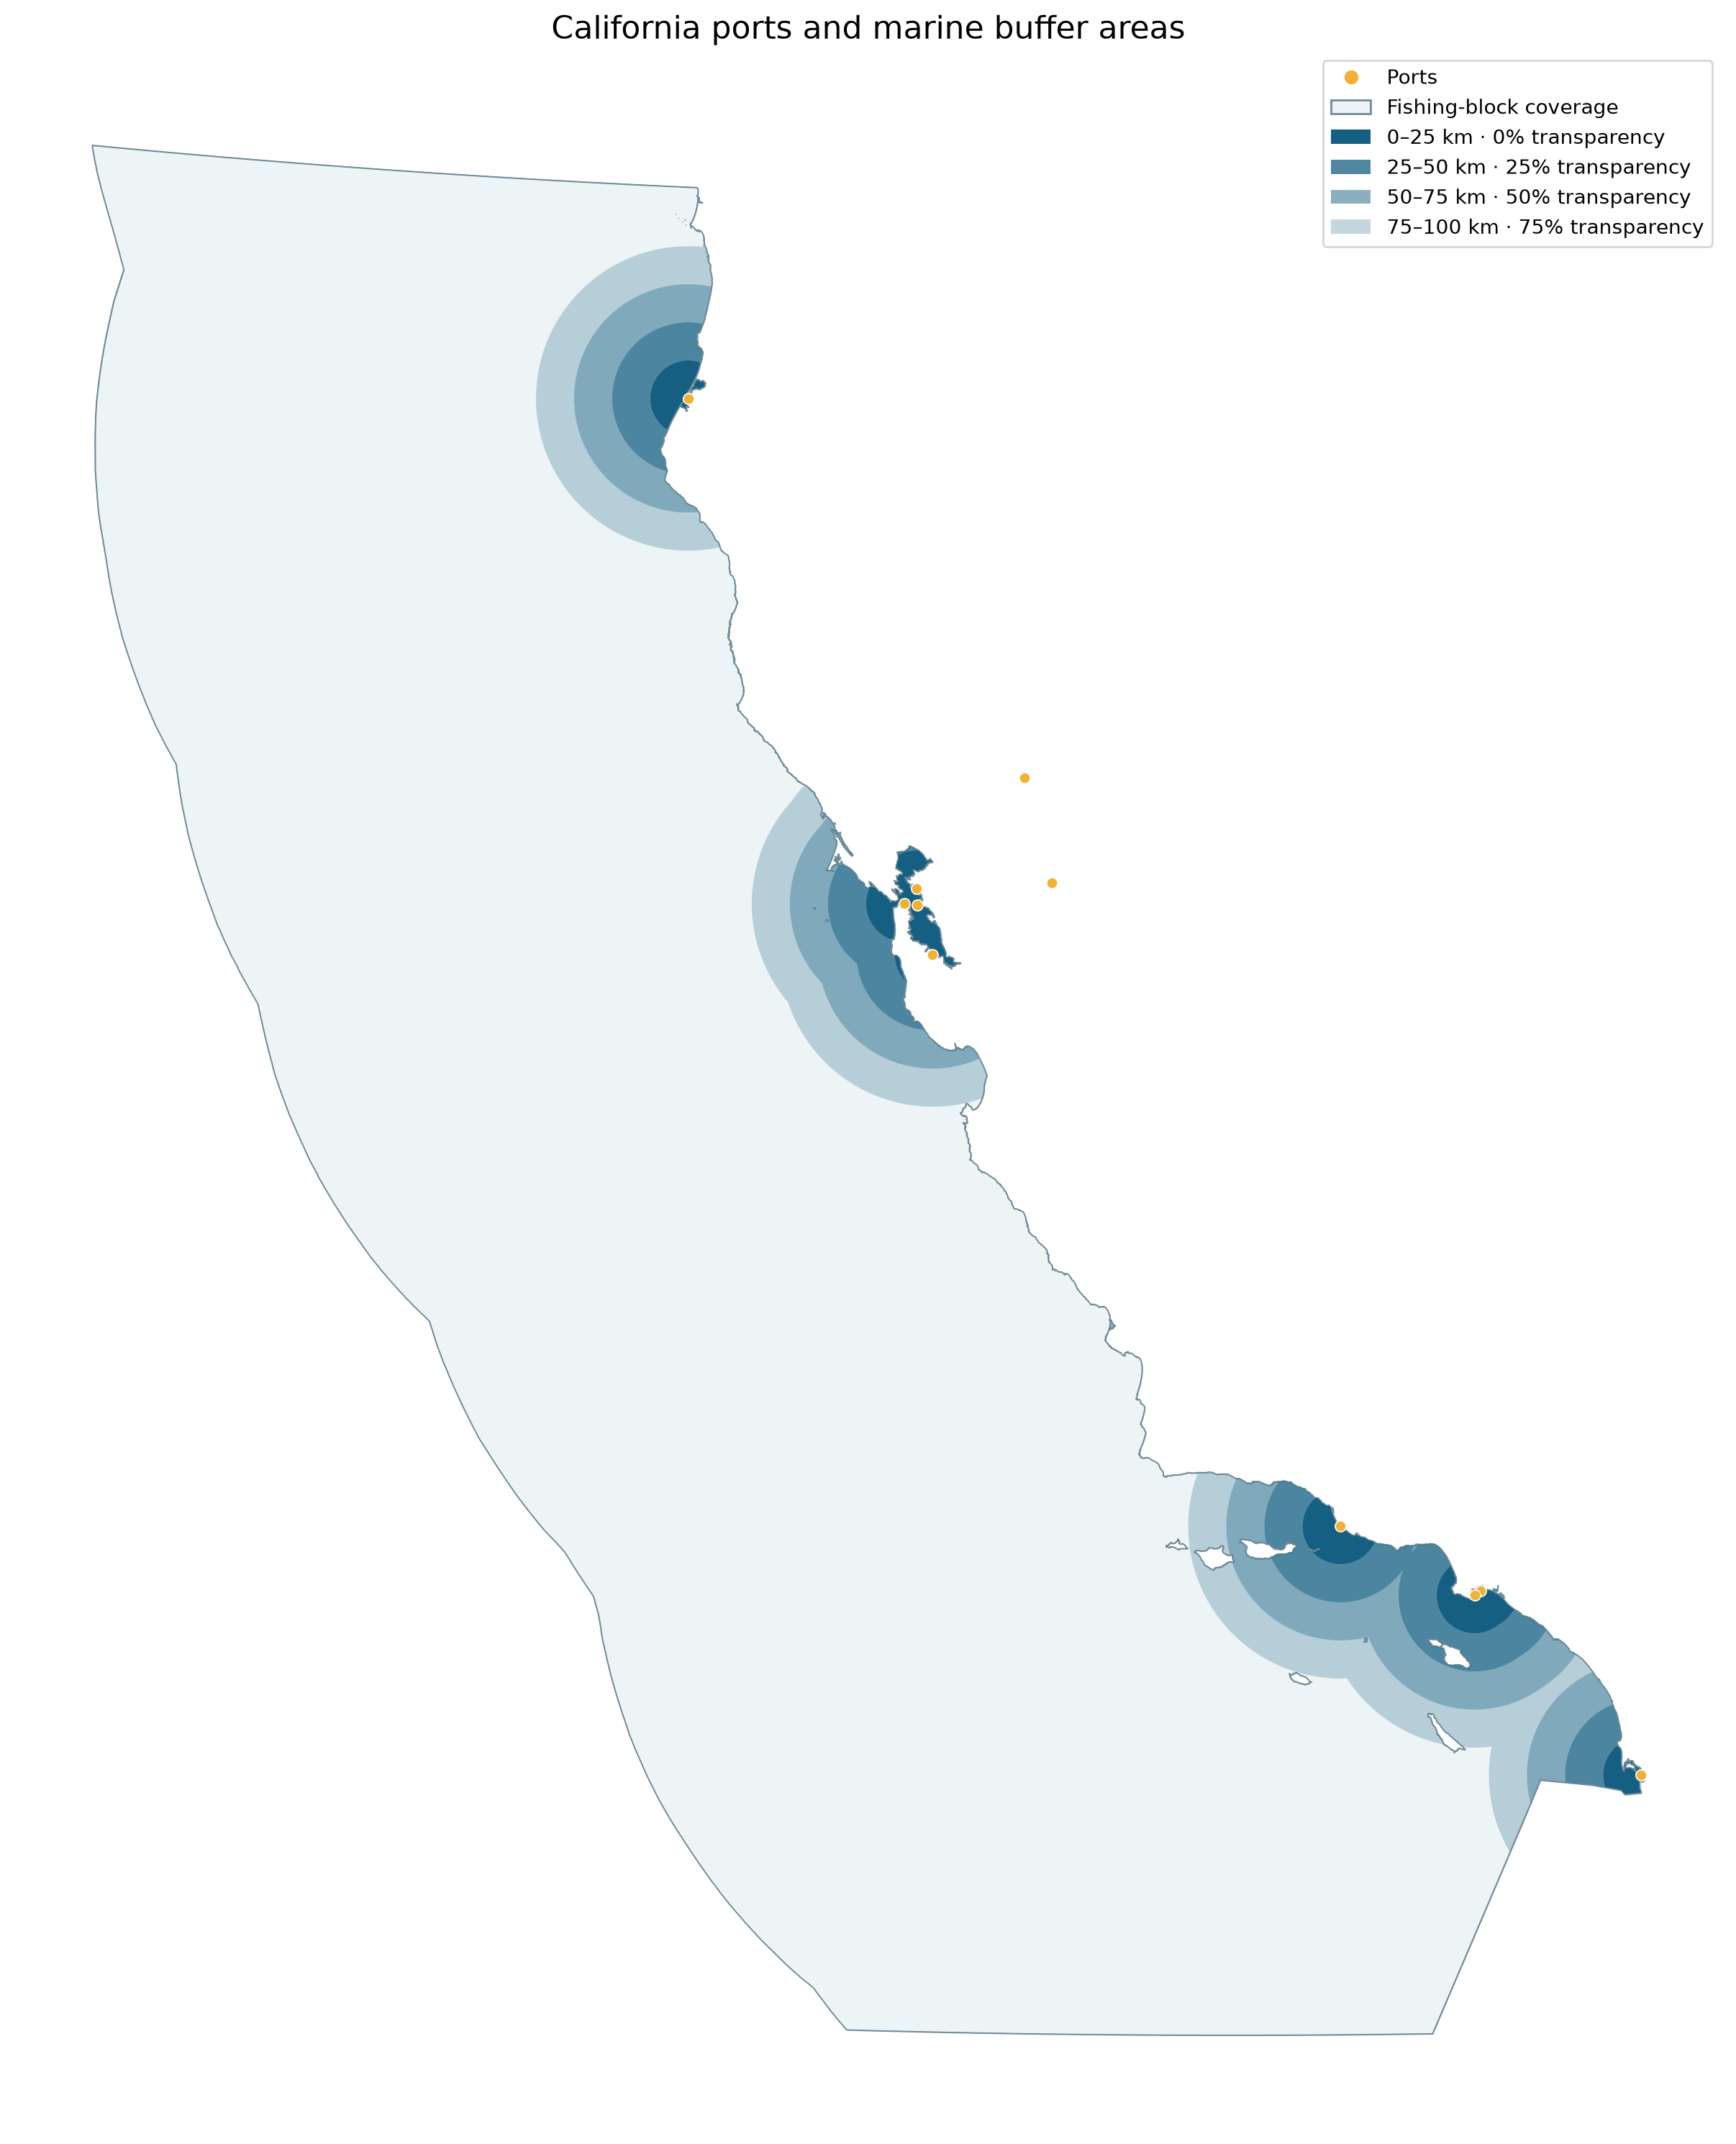

Saved: C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens\kelp-fisheries-stability-ML\Figures\California_Port_Buffers.png


In [41]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

project = Path(
    r"C:\Users\admin\OneDrive\Desktop\Research\Visiting Researcher Athens"
    r"\kelp-fisheries-stability-ML"
)

buffer_folder = project / "data" / "processed" / "port_buffers"
figures_folder = project / "Figures"
figures_folder.mkdir(parents=True, exist_ok=True)

# Load layers in the same projected CRS
fishing_area = gpd.read_file(
    project / "data" / "processed"
    / "California_Fishing_Block_Coverage.geojson"
).to_crs(epsg=3310)

ports = gpd.read_file(
    project / "data" / "California_Ports_-_OSPR_[ds353].geojson"
).to_crs(epsg=3310)

dark_blue = "#156082"

fig_buffers, ax = plt.subplots(figsize=(13, 15))

# Merged fishing blocks
fishing_area.plot(
    ax=ax,
    facecolor="#EDF4F6",
    edgecolor="#708C98",
    linewidth=0.6,
    zorder=1
)

# Largest buffer first
buffer_styles = [
    (100, 0.25),
    (75, 0.50),
    (50, 0.75),
    (25, 1.00)
]

# Dissolve each distance layer to avoid darker overlaps between ports
# Subtract inner layers to prevent transparency from accumulating
buffer_layers = {}

for distance_km, alpha in buffer_styles:
    layer = gpd.read_file(
        buffer_folder / f"Ports_Buffer_{distance_km}km.geojson"
    ).to_crs(epsg=3310)

    layer = layer.loc[
        layer.geometry.notna() & ~layer.geometry.is_empty,
        ["geometry"]
    ].copy()

    if not layer.empty:
        buffer_layers[distance_km] = layer.dissolve()

for distance_km, alpha in buffer_styles:
    if distance_km not in buffer_layers:
        continue

    band = buffer_layers[distance_km].copy()

    # Remove the next smaller buffer to create non-overlapping bands
    smaller_distances = [
        d for d in buffer_layers if d < distance_km
    ]

    if smaller_distances:
        inner = buffer_layers[max(smaller_distances)]
        band = gpd.overlay(
            band,
            inner,
            how="difference",
            keep_geom_type=True
        )

    if not band.empty:
        band.plot(
            ax=ax,
            facecolor=dark_blue,
            alpha=alpha,
            edgecolor="none",
            zorder=2
        )

# Fishing-area outline
fishing_area.boundary.plot(
    ax=ax,
    color="#708C98",
    linewidth=0.5,
    zorder=3
)

# Ports
ports.plot(
    ax=ax,
    color="#F2B134",
    edgecolor="white",
    linewidth=0.6,
    markersize=30,
    zorder=4
)

# Legend
legend_items = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#F2B134",
        markeredgecolor="white",
        markersize=8,
        label="Ports"
    ),
    Patch(
        facecolor="#EDF4F6",
        edgecolor="#708C98",
        label="Fishing-block coverage"
    )
]

for label, alpha in [
    ("0–25 km · 0% transparency", 1.00),
    ("25–50 km · 25% transparency", 0.75),
    ("50–75 km · 50% transparency", 0.50),
    ("75–100 km · 75% transparency", 0.25)
]:
    legend_items.append(
        Patch(facecolor=dark_blue, alpha=alpha, label=label)
    )

ax.legend(handles=legend_items, loc="upper right", frameon=True)
ax.set_title("California ports and marine buffer areas", fontsize=16)
ax.set_axis_off()

fig_buffers.tight_layout()

output_path = figures_folder / "California_Port_Buffers.png"

fig_buffers.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
print("Saved:", output_path)

Creae port Author-proposed catchment area and port map

Create violin plots of variable distributions